# Indiana 2024 General Election Precinct Conversion

This notebook combines 92 prepared county CSVs into a statewide results CSV and
an allocated precinct shapefile. It retains federal and state candidate contests,
five judicial-retention questions, and Statewide Question 1. Nongeographic
reporting units remain separate in the master CSV; their votes are allocated to
eligible precincts in the spatial output.

The county CSVs were extracted from official state and county sources. Prepared
boundaries include documented alignment corrections and reporting-unit splits.
The notebook retains these edits without modifying the geometry.

**Inputs:** County CSVs listed in `data/manifest.csv`, precinct boundaries in
`data/boundaries`, and candidate definitions and validation references in
`data/reference`. See `data/reference/README.txt` for source and preparation details.

**Outputs:**

- `in_2024_gen_prec.csv`: master precinct results.
- `in_2024_gen_all_prec.csv`: allocated attributes matching the shapefile.
- `in_2024_gen_prec.zip`: the all-contest shapefile and README.


## Setup

Run from the project folder containing `data/`. Requires pandas, NumPy, GeoPandas,
Shapely, pyogrio, Matplotlib, and IPython. All inputs are local; the notebook does
not download source files.


In [1]:
from __future__ import annotations

import re
import unicodedata
import warnings
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import PathCollection
import numpy as np
import pandas as pd
from IPython.display import display
from shapely import normalize

ROOT = Path.cwd()
DATA_ROOT = ROOT / "data"
REFERENCE = DATA_ROOT / "reference"
MANIFEST_PATH = DATA_ROOT / "manifest.csv"
BOUNDARY_PATH = DATA_ROOT / "boundaries/in_2024_prepared_precincts.gpkg"
OUTPUT_PATH = ROOT / "in_2024_gen_prec.csv"
ALLOCATED_PATH = ROOT / "in_2024_gen_all_prec.csv"
PACKAGE_DIR = ROOT / "in_2024_gen_prec"
PACKAGE_ZIP = ROOT / "in_2024_gen_prec.zip"
LAYER_NAME = "in_2024_gen_all_prec"
ID_COLUMNS = ["UNIQUE_ID", "COUNTYFP", "County", "Precinct"]
DISTRICT_COLUMNS = ["CONG_DIST", "SLDU_DIST", "SLDL_DIST"]
SOURCE_COLUMNS = [
    "county",
    "precinct",
    "office",
    "district",
    "party",
    "candidate",
    "votes",
]
RESULT_KEY_COLUMNS = SOURCE_COLUMNS[:-1]
PUBLISHABLE_STATUSES = {"ready", "accepted_discrepancy"}
PLOT_COVERAGE = True
PLOT_DETAILED_COVERAGE = False

PARTY_CODE = {
    "DEM": "D",
    "REP": "R",
    "LIB": "L",
    "WTP": "T",
    "IND": "I",
    "WI": "O",
}
FEDERAL_OFFICES = {"President", "U.S. Senate", "U.S. House"}

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)

# Values are (congressional district, optional precinct prefix, expected precinct count).
FEDERAL_ALLOCATION_SCOPES = {
    ("Cass", "Federal Only"): ("4", None, 20),
    ("Fountain", "FED8"): ("8", None, 11),
    ("Fulton", "FED02"): ("2", None, 17),
    ("Monroe", "BLOOM FEDERAL"): ("9", "BLOOMINGTON ", 24),
    ("Ripley", "FED9"): ("9", None, 36),
    ("Washington", "FEDERAL"): ("9", None, 22),
}

ZERO_ONLY_ROWS = {
    ("Cass", "President Only"),
    ("Elkhart", "Baugo A Nv"),
    ("Newton", "FED04"),
}


## Input


In [2]:
required_inputs = [MANIFEST_PATH, BOUNDARY_PATH] + [
    REFERENCE / name
    for name in [
        "candidates.csv",
        "official_controls.csv",
        "accepted_discrepancies.csv",
        "spatial_readme.txt",
    ]
]
missing_inputs = [str(path.relative_to(ROOT)) for path in required_inputs if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError(f"Missing prepared inputs: {missing_inputs}")
candidate_roster = pd.read_csv(REFERENCE / "candidates.csv", dtype=str, keep_default_na=False)
assert candidate_roster.columns.tolist() == [
    "office",
    "district",
    "party",
    "candidate",
]
assert not candidate_roster.duplicated().any()
manifest = pd.read_csv(MANIFEST_PATH, dtype=str, keep_default_na=False)
assert len(manifest) == 92
assert manifest.county.is_unique and manifest.county_fips.is_unique
assert set(manifest.status).issubset(PUBLISHABLE_STATUSES)
assert manifest.county_fips.str.fullmatch(r"\d{3}").all()
manifest = manifest.sort_values("county_fips", kind="stable").reset_index(drop=True)
missing_counties = [
    spec.county
    for spec in manifest.itertuples()
    if not (DATA_ROOT / spec.county / spec.output_filename).is_file()
]
if missing_counties:
    raise FileNotFoundError(f"Missing county CSVs: {missing_counties}")
print(f"County files: {len(manifest)}; named candidates: {len(candidate_roster)}")
display(manifest[["county", "source_kind", "status"]].head())


County files: 92; named candidates: 244


,county,source_kind,status
0,Adams,state_enr,ready
1,Allen,county_artifact_mirror,ready
2,Bartholomew,state_enr,ready
3,Benton,county_artifact_mirror,accepted_discrepancy
4,Blackford,county_artifact_mirror,ready


## CSV Helper Functions

Define functions to read county results, assign vote fields, build the master
table, and validate it. The following sections call these functions.


In [3]:
# Vote-field definitions

def surname_fragment(candidate: str) -> str:
    """Return three ASCII surname letters for the first candidate on a ticket.

    Ignore parenthetical labels and generational suffixes, and fold accents so
    compact field names remain compatible with the existing shapefile schema.
    """
    first_candidate = candidate.split("/", 1)[0]
    clean = re.sub(r"\([^)]*\)", " ", first_candidate)
    words = re.findall(r"[A-Za-zÀ-ÖØ-öø-ÿ]+", clean)
    if words[-1].upper() in {"JR", "SR", "II", "III", "IV"}:
        words.pop()
    surname = unicodedata.normalize("NFKD", words[-1])
    surname = "".join(character for character in surname if character.isascii())
    return surname[:3].upper()


def field_name(office: str, district: str, party: str, surname: str) -> str:
    """Return the compact RDH field name for one candidate result."""
    prefixes = {
        "President": "G24PRE",
        "U.S. Senate": "G24USS",
        "Governor": "G24GOV",
        "Attorney General": "G24ATG",
    }
    if office == "U.S. House":
        prefix = f"GCON{int(district):02d}"
    elif office == "State Senate":
        prefix = f"GSU{int(district):02d}"
    elif office == "State House":
        prefix = f"GSL{int(district):03d}"
    elif office in prefixes:
        prefix = prefixes[office]
    else:
        raise ValueError(f"Unsupported candidate office: {office}")
    return f"{prefix}{PARTY_CODE[party]}{surname}"


def candidate_field_maps(roster: pd.DataFrame) -> tuple[
    dict[tuple[str, str, str, str], str],
    dict[tuple[str, str, str], str],
]:
    """Build base output fields and the named-candidate write-in lookup.

    Base keys contain office, district, party, and candidate. The write-in lookup
    omits party so a named write-in can count toward the matching ballot candidate.
    Positive state write-ins are added separately after reading county results.
    """
    # Candidate keys are (office, district, party, candidate).
    named_field_by_key = {
        (office, district, party, candidate): field_name(
            office, district, party, surname_fragment(candidate)
        )
        for office, district, party, candidate in roster.itertuples(index=False, name=None)
    }
    ballot_field_by_write_in = {
        (office, district, candidate): field
        for (office, district, party, candidate), field in named_field_by_key.items()
    }

    # Federal contests always retain a generic write-in field, even at zero votes.
    federal_write_in_fields = {}
    for office, district in [
        ("President", ""),
        ("U.S. Senate", ""),
        *[("U.S. House", str(district)) for district in range(1, 10)],
    ]:
        federal_write_in_fields[office, district, "WI", "Write-In"] = field_name(
            office, district, "WI", "WRI"
        )

    question_fields = {
        ("Judicial Retention", str(judge), "", choice): f"G24J{judge}{choice}"
        for judge in range(1, 6)
        for choice in ("YES", "NO")
    }
    question_fields.update(
        {("Statewide Question", "1", "", choice): f"G24Q1{choice}" for choice in ("YES", "NO")}
    )
    base_field_by_key = named_field_by_key | federal_write_in_fields | question_fields
    return base_field_by_key, ballot_field_by_write_in


# County input reading

def load_county_rows(manifest: pd.DataFrame, data_root: Path = DATA_ROOT) -> pd.DataFrame:
    """Combine prepared county files into one row per precinct/contest/option.

    Read identifiers as text to preserve blanks and leading zeros, then convert
    votes to nonnegative integers. Reject duplicate source keys before combining.
    """
    frames = []
    for spec in manifest.itertuples(index=False):
        path = data_root / spec.county / spec.output_filename
        frame = pd.read_csv(path, dtype=str, keep_default_na=False)
        # Extra CSV fields can become an implicit index instead of a read error.
        if frame.columns.tolist() != SOURCE_COLUMNS or not isinstance(frame.index, pd.RangeIndex):
            raise ValueError(f"Unexpected county CSV schema: {path}")
        if set(frame["county"]) != {spec.county}:
            raise ValueError(f"Unexpected county labels: {path}")
        if frame.duplicated(RESULT_KEY_COLUMNS).any():
            raise ValueError(f"Duplicate source result keys: {path}")
        frame["votes"] = pd.to_numeric(frame["votes"], errors="raise")
        assert (frame["votes"] % 1 == 0).all() and (frame["votes"] >= 0).all(), path
        frame["votes"] = frame["votes"].astype("int64")
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)


# Reporting-unit exceptions and vote aggregation

def remove_monroe_zero_units(rows: pd.DataFrame) -> pd.DataFrame:
    """Drop Monroe's zero-only PRES rows when the unsuffixed unit also exists.

    These duplicate reporting labels add no votes. Keep every nonzero PRES row
    and every zero-only row without an unsuffixed counterpart.
    """
    unit_totals = rows.groupby(["county", "precinct"], dropna=False)["votes"].sum()
    monroe_units = set(rows.loc[rows["county"].eq("Monroe"), "precinct"])
    zero_duplicates = {
        precinct
        for county, precinct in unit_totals[unit_totals.eq(0)].index
        if county == "Monroe"
        and precinct.endswith(" - PRES")
        and precinct.removesuffix(" - PRES") in monroe_units
    }
    return rows.loc[~rows["county"].eq("Monroe") | ~rows["precinct"].isin(zero_duplicates)].copy()


def state_write_in_fields(
    rows: pd.DataFrame,
) -> dict[tuple[str, str, str, str], str]:
    """Create state Other / Write-In fields only for positive source write-ins.

    Zero-only state records do not add output columns. Decide field presence
    before routing named write-ins to ballot candidates, preserving the schema
    even when all positive write-ins later map to named-candidate fields.
    """
    write_ins = rows.loc[
        rows["party"].eq("WI") & ~rows["office"].isin(FEDERAL_OFFICES) & rows["votes"].gt(0)
    ]
    keys = {
        (office, district, "WI", "Write-In")
        for office, district in write_ins[["office", "district"]].itertuples(index=False, name=None)
    }
    return {key: field_name(key[0], key[1], "WI", "WRI") for key in sorted(keys)}


def write_in_field(
    key: tuple[str, str, str],
    votes: int,
    field_by_key: dict[tuple[str, str, str, str], str],
    ballot_fields: dict[tuple[str, str, str], str],
    ballot_names: set[str],
) -> str:
    """Return the output field for an (office, district, candidate) write-in key.

    A known ballot candidate must match the reported office and district. Other
    names use the generic OWRI field. Return an empty string only for a zero-vote
    row whose contest has no write-in output field.
    """
    office, district, candidate = key
    if candidate in ballot_names:
        if key not in ballot_fields:
            raise ValueError(f"Write-in candidate does not match the contest: {key}")
        return ballot_fields[key]
    field = field_by_key.get((office, district, "WI", "Write-In"), "")
    assert field or votes == 0, (key, votes)
    return field


def aggregate_vote_fields(
    rows: pd.DataFrame,
    field_by_key: dict[tuple[str, str, str, str], str],
    ballot_fields: dict[tuple[str, str, str], str],
) -> pd.DataFrame:
    """Map source rows to vote fields and sum by county, precinct, and field.

    Return county, precinct, field, and votes, with one row per unique key.
    Named write-ins count toward their ballot candidate; other names share an
    Other / Write-In field. Drop only zero-vote rows without an output field.
    """
    field_results = rows.copy()
    ballot_names = {candidate for _, _, candidate in ballot_fields}
    fields = []
    for row in field_results.itertuples(index=False):
        key = (row.office, row.district, row.party, row.candidate)
        if row.party != "WI":
            if key not in field_by_key:
                raise ValueError(f"Unmapped candidate or ballot option: {key}")
            fields.append(field_by_key[key])
            continue

        fields.append(
            write_in_field(
                (row.office, row.district, row.candidate),
                row.votes,
                field_by_key,
                ballot_fields,
                ballot_names,
            )
        )

    field_results["field"] = fields
    field_results = field_results.loc[field_results["field"].ne("")]
    field_results = field_results.groupby(
        ["county", "precinct", "field"], as_index=False, sort=False
    )["votes"].sum()
    required_fields = {field for key, field in field_by_key.items() if key[2] != "WI"}
    assert required_fields.issubset(field_results["field"])
    return field_results


# Master CSV construction

def build_master_csv_table(
    field_results: pd.DataFrame,
    manifest: pd.DataFrame,
    field_by_key: dict[tuple[str, str, str, str], str],
) -> pd.DataFrame:
    """Pivot county/precinct/field totals to one row per reporting unit.

    Add public identifiers, fill absent vote fields with zero, and sort by county
    code and precinct label. This order also breaks ties during later allocation.
    """
    assert len(field_by_key) == len(
        set(field_by_key.values())
    ), "Duplicate compact vote-field names"
    vote_fields = sorted(field_by_key.values())
    wide = field_results.pivot(index=["county", "precinct"], columns="field", values="votes")
    wide = wide.reindex(columns=vote_fields, fill_value=0).fillna(0).astype("int64").reset_index()
    wide.columns.name = None
    fips = manifest.set_index("county")["county_fips"]
    wide.insert(0, "COUNTYFP", wide["county"].map(fips))
    wide.insert(0, "UNIQUE_ID", wide["county"] + "-:-" + wide["precinct"])
    wide = wide.rename(columns={"county": "County", "precinct": "Precinct"})
    wide = wide[ID_COLUMNS + vote_fields]
    wide = wide.sort_values(["COUNTYFP", "Precinct"], kind="stable").reset_index(drop=True)

    output_totals = wide[vote_fields].sum().sort_index()
    source_totals = (
        field_results.groupby("field")["votes"]
        .sum()
        .reindex(vote_fields, fill_value=0)
        .sort_index()
    )
    pd.testing.assert_series_equal(output_totals, source_totals, check_names=False)
    return wide


# Master CSV validation

def compare_official_totals(rows: pd.DataFrame) -> pd.DataFrame:
    """Return source differences and reject changes to the accepted discrepancies.

    Compare named candidates and ballot options only. Generic write-in marks are
    not directly comparable to the state's accepted named write-in totals.
    """
    keys = ["county", "office", "district", "party", "candidate"]
    controls = pd.read_csv(REFERENCE / "official_controls.csv", dtype=str, keep_default_na=False)
    assert controls.columns.tolist() == keys + ["votes"]
    assert not controls.duplicated(keys).any()
    controls["votes"] = pd.to_numeric(controls.votes, errors="raise").astype("int64")
    actual = rows.loc[rows.party.ne("WI")].groupby(keys).votes.sum().rename("actual_votes")
    expected = controls.loc[controls.party.ne("WI")].set_index(keys).votes.rename("expected_votes")
    comparison = pd.concat([actual, expected], axis=1).fillna(0).astype("int64")
    comparison["difference"] = comparison.actual_votes - comparison.expected_votes
    differences = comparison.loc[comparison.difference.ne(0)].reset_index()
    accepted = pd.read_csv(
        REFERENCE / "accepted_discrepancies.csv",
        dtype={key: str for key in keys},
        keep_default_na=False,
    ).drop(columns="source")
    accepted = accepted.sort_values(keys).reset_index(drop=True)
    differences = differences.sort_values(keys).reset_index(drop=True)
    if not differences.equals(accepted):
        changes = differences.merge(
            accepted, on=keys, how="outer", suffixes=("_current", "_accepted")
        )
        changed = pd.Series(False, index=changes.index)
        for column in ["actual_votes", "expected_votes", "difference"]:
            changed |= changes[f"{column}_current"].ne(changes[f"{column}_accepted"])
        display(changes.loc[changed])
    pd.testing.assert_frame_equal(differences, accepted)
    return differences


def review_results(
    output: pd.DataFrame,
    rows: pd.DataFrame,
    field_by_key: dict[tuple[str, str, str, str], str],
    ballot_fields: dict[tuple[str, str, str], str],
) -> pd.DataFrame:
    """Check output shape, field definitions, and source vote conservation."""
    vote_fields = sorted(field_by_key.values())
    values = output[vote_fields]
    source_write_ins = rows.loc[rows.party.eq("WI")].copy()
    keys = list(
        source_write_ins[["office", "district", "candidate"]].itertuples(index=False, name=None)
    )
    unmatched = ~pd.Series(keys, index=source_write_ins.index).isin(ballot_fields)
    expected_other = int(source_write_ins.loc[unmatched, "votes"].sum())
    other_fields = sorted({field for key, field in field_by_key.items() if key[2] == "WI"})
    identifiers = output[ID_COLUMNS]
    assert output.UNIQUE_ID.is_unique, "Duplicate reporting-unit IDs"
    assert identifiers.notna().all().all() and identifiers.ne("").all().all()
    assert output.columns.tolist() == ID_COLUMNS + vote_fields
    assert values.notna().all().all() and values.ge(0).all().all()
    assert all(pd.api.types.is_integer_dtype(values[field]) for field in vote_fields)

    checks = [
        ("Reporting units", len(output), 5_189),
        ("Counties", output.COUNTYFP.nunique(), 92),
        ("Vote fields", len(vote_fields), 268),
        ("Source votes", int(values.to_numpy().sum()), int(rows.votes.sum())),
        ("Other / Write-In votes", int(output[other_fields].to_numpy().sum()), expected_other),
    ]
    return pd.DataFrame(checks, columns=["check", "actual", "expected"])


## Build Precinct CSV


In [4]:
base_field_by_key, ballot_field_by_write_in = candidate_field_maps(candidate_roster)
county_rows = load_county_rows(manifest)
reporting_rows = remove_monroe_zero_units(county_rows)
field_by_key = base_field_by_key | state_write_in_fields(reporting_rows)
field_results = aggregate_vote_fields(reporting_rows, field_by_key, ballot_field_by_write_in)
master_results = build_master_csv_table(field_results, manifest, field_by_key)
vote_fields = sorted(field_by_key.values())
print(
    f"Output shape: {len(master_results):,} reporting units × {len(master_results.columns)} columns"
)
display(master_results.iloc[:, :12].head())


Output shape: 5,189 reporting units × 272 columns


,UNIQUE_ID,COUNTYFP,County,Precinct,G24ATGDWEL,G24ATGRROK,G24GOVDMCC,G24GOVLRAI,G24GOVOWRI,G24GOVRBRA,G24J1NO,G24J1YES
0,Adams-:-Berne A,001,Adams,Berne A,130,498,165,32,0,483,0,0
1,Adams-:-Berne B,001,Adams,Berne B,124,541,146,38,0,548,0,0
2,Adams-:-Berne C,001,Adams,Berne C,116,464,142,11,0,492,0,0
3,Adams-:-Blue Creek,001,Adams,Blue Creek,28,177,39,12,0,178,0,0
4,Adams-:-Countywide Questions,001,Adams,Countywide Questions,0,0,0,0,0,0,2589,7737


## Validate Precinct CSV


In [5]:
csv_checks = review_results(master_results, county_rows, field_by_key, ballot_field_by_write_in)
display(csv_checks)
assert csv_checks.actual.eq(csv_checks.expected).all(), "CSV validation failed"
discrepancies = compare_official_totals(county_rows)
print(
    f"Official comparisons: {len(discrepancies)} accepted differences in {discrepancies.county.nunique()} counties"
)
display(discrepancies.groupby("county").size().rename("accepted differences").to_frame())


,check,actual,expected
0,Reporting units,5189,5189
1,Counties,92,92
2,Vote fields,268,268
3,Source votes,30678657,30678657
4,Other / Write-In votes,6129,6129


Official comparisons: 114 accepted differences in 17 counties


,accepted differences
county,
Benton,3
Brown,2
Clark,4
Dubois,18
Floyd,12
Fountain,1
LaPorte,1
Perry,8
Porter,3


## Export Precinct CSV


In [6]:
master_results.to_csv(OUTPUT_PATH, index=False, lineterminator="\n")
reopened = pd.read_csv(OUTPUT_PATH, dtype={"COUNTYFP": str})
pd.testing.assert_frame_equal(reopened, master_results)
print(f"Wrote and verified {OUTPUT_PATH.name}")


Wrote and verified in_2024_gen_prec.csv


## Precinct Shapefile

Join results to prepared boundaries by county code and precinct label. No boundary
edits are made here. Retain eight map-only areas with zero votes and exclude them
from allocation.

Allocate nongeographic votes within the county and district scopes defined below.
Use each candidate or ballot option's original precinct vote shares as weights.
If those votes are all zero, use precinct totals across all vote fields instead.
Largest-remainder rounding preserves integer vote totals.

Countywide questions use the total-vote fallback because only county totals are
available. Their precinct allocations are estimates, not reported results.

Nine coverage maps show precincts with any votes in each office or question
group in blue; precincts with no votes in that group are gray. These summaries
do not show candidate-specific gaps. Set `PLOT_DETAILED_COVERAGE = True` to
inspect all vote fields, or `PLOT_COVERAGE = False` to skip maps. Geometry is
simplified only for display; exports retain the full prepared geometry.


### Spatial Helper Functions

Define functions for boundary matching, vote allocation, validation, export,
and plotting. The three execution steps below build, export, and map the results.


In [7]:
# Boundary matching and district checks

def validate_boundary_input(boundaries: gpd.GeoDataFrame) -> None:
    """Check the prepared layer's identifiers, geometry, and eight map-only areas."""
    assert boundaries.columns.tolist() == ID_COLUMNS + DISTRICT_COLUMNS + [
        "source_only",
        "geometry",
    ]
    assert len(boundaries) == 5_146 and boundaries.UNIQUE_ID.is_unique
    assert boundaries.source_only.isin([True, False]).all() and boundaries.source_only.sum() == 8
    identifiers = boundaries[ID_COLUMNS + DISTRICT_COLUMNS]
    assert identifiers.notna().all().all() and identifiers.ne("").all().all()
    assert boundaries.crs is not None
    assert boundaries.geometry.notna().all() and (~boundaries.geometry.is_empty).all()
    assert boundaries.geometry.is_valid.all()


def join_boundaries(
    geographic: pd.DataFrame,
    boundaries: gpd.GeoDataFrame,
    vote_fields: list[str],
) -> gpd.GeoDataFrame:
    """Match prepared county/precinct labels, retaining map-only areas with zero votes.

    Return one row per prepared polygon with reported votes and district fields.
    Prepared labels already match results; reject unexpected unmatched rows
    instead of guessing a label or dropping it. Map-only polygons receive zeros.
    """
    matched_precincts = boundaries.merge(
        geographic,
        on=["COUNTYFP", "Precinct"],
        how="outer",
        validate="one_to_one",
        indicator=True,
        suffixes=("_boundary", ""),
    )
    unexpected = matched_precincts.loc[
        matched_precincts._merge.eq("right_only")
        | (matched_precincts._merge.eq("left_only") & ~matched_precincts.source_only.eq(True))
        | (matched_precincts._merge.eq("both") & matched_precincts.source_only.eq(True))
    ]
    if not unexpected.empty:
        display(unexpected[["COUNTYFP", "Precinct", "_merge"]])
        raise ValueError("Unexpected unmatched or map-only reporting units")
    matched = matched_precincts._merge.eq("both")
    assert matched.sum() == 5_138
    for field in ["UNIQUE_ID", "County"]:
        assert matched_precincts.loc[matched, field].equals(
            matched_precincts.loc[matched, f"{field}_boundary"]
        ), field
        matched_precincts[field] = matched_precincts[field].fillna(
            matched_precincts[f"{field}_boundary"]
        )
    matched_precincts[vote_fields] = matched_precincts[vote_fields].fillna(0).astype("int64")
    matched_precincts = matched_precincts[
        ID_COLUMNS + DISTRICT_COLUMNS + vote_fields + ["source_only", "geometry"]
    ]
    matched_precincts = matched_precincts.rename(columns={"source_only": "_source_only"})
    matched_precincts = matched_precincts.sort_values(
        ["COUNTYFP", "Precinct"], kind="stable"
    ).reset_index(drop=True)
    matched_votes = matched_precincts.loc[~matched_precincts._source_only].set_index("UNIQUE_ID")[
        vote_fields
    ]
    pd.testing.assert_frame_equal(
        matched_votes, geographic.set_index("UNIQUE_ID").loc[matched_votes.index, vote_fields]
    )
    return gpd.GeoDataFrame(matched_precincts, geometry="geometry", crs=boundaries.crs)


def validate_reported_districts(
    matched_precincts: gpd.GeoDataFrame, vote_fields: list[str]
) -> None:
    """Check positive legislative votes against the precinct's assigned district.

    GCON and GSU encode two district digits; GSL encodes three. Zero votes do not
    establish membership, so only positive values constrain the district check.
    """
    for prefix, digits, district_field in [
        ("GCON", 2, "CONG_DIST"),
        ("GSL", 3, "SLDL_DIST"),
        ("GSU", 2, "SLDU_DIST"),
    ]:
        for field in [c for c in vote_fields if c.startswith(prefix)]:
            district = int(field[len(prefix) : len(prefix) + digits])
            mismatched = matched_precincts[field].gt(0) & matched_precincts[district_field].astype(
                int
            ).ne(district)
            if mismatched.any():
                display(matched_precincts.loc[mismatched, ID_COLUMNS + [district_field, field]])
                raise ValueError(f"Votes outside the assigned district: {field}")


# Nongeographic classification and allocation

def largest_remainder(total: int, weights: pd.Series) -> pd.Series:
    """Return integer shares indexed like weights, preserving the source total.

    Assign floor quotas first, then give residual votes to the largest fractional
    remainders. Stable sorting breaks ties in the established precinct order.
    """
    assert total >= 0
    weights = weights.astype("float64")
    assert (weights >= 0).all() and weights.sum() > 0

    quotas = weights / weights.sum() * total
    shares = np.floor(quotas).astype("int64")
    remainder = total - int(shares.sum())
    if remainder:
        order = (quotas - shares).sort_values(ascending=False, kind="stable").index[:remainder]
        shares.loc[order] += 1
    assert int(shares.sum()) == total
    return shares


def allocation_targets(matched_precincts: gpd.GeoDataFrame, county: str, precinct: str) -> pd.Index:
    """Return eligible row indices for a county question or federal vote batch.

    Questions cover every physical precinct in the county. Federal batches are
    limited to their congressional district; Monroe's batch is further limited
    to Bloomington precincts. Map-only areas never receive allocated votes.
    """
    if precinct == "Countywide Questions":
        return matched_precincts.index[
            (matched_precincts.County == county) & ~matched_precincts._source_only
        ]

    district, precinct_prefix, expected_count = FEDERAL_ALLOCATION_SCOPES[county, precinct]
    district_values = matched_precincts.CONG_DIST.astype(str).str.lstrip("0")
    target = (
        (matched_precincts.County == county)
        & (district_values == district)
        & ~matched_precincts._source_only
    )
    if precinct_prefix is not None:
        target &= matched_precincts.Precinct.str.startswith(precinct_prefix)
    indices = matched_precincts.index[target]
    assert len(indices) == expected_count, (
        county,
        precinct,
        len(indices),
        expected_count,
    )
    return indices


def partition_reporting_units(
    master_results: pd.DataFrame, vote_fields: list[str]
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return geographic results and the 48 nongeographic allocation batches.

    Identify federal and zero-only rows by exact county/precinct keys. Keep
    unknown labels in the geographic table so the boundary join rejects them.
    The three zero-only rows remain solely in the master CSV.
    """
    keys = pd.MultiIndex.from_frame(master_results[["County", "Precinct"]])
    questions = master_results.Precinct.eq("Countywide Questions")
    federal = keys.isin(FEDERAL_ALLOCATION_SCOPES)
    zero_only = keys.isin(ZERO_ONLY_ROWS)
    nongeographic = questions | federal | zero_only
    assert questions.sum() == 42 and federal.sum() == 6 and zero_only.sum() == 3
    assert nongeographic.sum() == 51
    assert master_results.loc[zero_only, vote_fields].eq(0).all().all()
    allocation_batches = pd.concat(
        [master_results.loc[questions], master_results.loc[federal]], ignore_index=True
    )
    return master_results.loc[~nongeographic].copy(), allocation_batches


def allocate_nongeographic_votes(
    matched_precincts: gpd.GeoDataFrame, allocation_batches: pd.DataFrame, vote_fields: list[str]
) -> gpd.GeoDataFrame:
    """Add whole-number shares of each batch to its eligible precincts.

    Return a copy of the matched precincts with allocated votes added. Use the
    original reported votes as weights so earlier batches cannot affect later
    ones. If a field has no reported votes, use totals across all vote fields;
    countywide questions need this fallback because they have no precinct votes.
    """
    output = matched_precincts.copy()
    fallback_weights = matched_precincts[vote_fields].sum(axis=1)
    for row in allocation_batches.to_dict("records"):
        target = allocation_targets(matched_precincts, row["County"], row["Precinct"])
        assert len(target) > 0
        for field in vote_fields:
            total = int(row[field])
            if total == 0:
                continue
            weights = matched_precincts.loc[target, field]
            if weights.sum() == 0:
                weights = fallback_weights.loc[target]
            additions = largest_remainder(total, weights)
            output.loc[target, field] += additions
    return output


# Spatial validation

def validate_allocations(
    allocated_precincts: gpd.GeoDataFrame,
    matched_precincts: gpd.GeoDataFrame,
    allocation_batches: pd.DataFrame,
    vote_fields: list[str],
) -> None:
    """Check that each batch's additions stay within its scope and preserve its total.

    In this dataset, batches within a county occupy distinct vote fields. Their
    deltas can therefore be checked against the source batch independently.
    County totals are checked separately in the spatial summary.
    """
    assert allocated_precincts.UNIQUE_ID.equals(matched_precincts.UNIQUE_ID)
    assert all(pd.api.types.is_integer_dtype(allocated_precincts[c]) for c in vote_fields)
    delta = allocated_precincts[vote_fields] - matched_precincts[vote_fields]
    assert delta.ge(0).all().all(), "Allocation reduced reported precinct votes"
    positive_batches = (
        allocation_batches[vote_fields].gt(0).groupby(allocation_batches.County).sum()
    )
    assert positive_batches.le(1).all().all(), "Overlapping county/field batches"
    for row in allocation_batches.to_dict("records"):
        target = allocation_targets(matched_precincts, row["County"], row["Precinct"])
        outside = matched_precincts.index[matched_precincts.County.eq(row["County"])].difference(
            target
        )
        for field in vote_fields:
            if row[field]:
                if row["Precinct"] == "Countywide Questions":
                    assert (
                        matched_precincts.loc[target, field].eq(0).all()
                    ), "Question allocation requires fallback weights"
                assert int(delta.loc[target, field].sum()) == int(row[field]), (
                    row["UNIQUE_ID"],
                    field,
                )
                assert delta.loc[outside, field].eq(0).all(), (
                    row["UNIQUE_ID"],
                    field,
                )


def review_spatial(
    allocated_precincts: gpd.GeoDataFrame,
    boundaries: gpd.GeoDataFrame,
    master_results: pd.DataFrame,
    vote_fields: list[str],
) -> pd.DataFrame:
    """Check allocated precincts against prepared geometry and master county totals."""
    assert allocated_precincts.UNIQUE_ID.is_unique, "Duplicate mapped-unit IDs"
    assert set(allocated_precincts.UNIQUE_ID) == set(boundaries.UNIQUE_ID)
    expected = boundaries.set_index("UNIQUE_ID").loc[allocated_precincts.UNIQUE_ID]
    assert allocated_precincts.crs == boundaries.crs
    assert np.array_equal(
        normalize(allocated_precincts.geometry).to_wkb().to_numpy(),
        normalize(expected.geometry).to_wkb().to_numpy(),
    ), "Prepared geometry changed"

    county_totals = allocated_precincts.groupby("COUNTYFP")[vote_fields].sum()
    source_totals = master_results.groupby("COUNTYFP")[vote_fields].sum()
    changed_totals = int(county_totals.ne(source_totals).sum().sum())
    map_only_votes = int(
        allocated_precincts.loc[allocated_precincts._source_only, vote_fields].to_numpy().sum()
    )
    checks = [
        ("Mapped areas", len(allocated_precincts), 5_146),
        ("Map-only areas", int(allocated_precincts._source_only.sum()), 8),
        ("Map-only votes", map_only_votes, 0),
        ("Changed county/field totals", changed_totals, 0),
    ]
    return pd.DataFrame(checks, columns=["check", "actual", "expected"])


# Spatial workflow

def build_spatial_results(
    master_results: pd.DataFrame, vote_fields: list[str], boundary_path: Path
) -> tuple[gpd.GeoDataFrame, pd.DataFrame]:
    """Join and allocate master results, returning validated precincts and checks.

    Keep matching and allocation intermediates local. Validate each stage before
    returning a layer ready for export; any failed check stops the workflow.
    """
    boundaries = gpd.read_file(boundary_path, layer="precincts")
    validate_boundary_input(boundaries)
    geographic, allocation_batches = partition_reporting_units(master_results, vote_fields)
    matched_precincts = join_boundaries(geographic, boundaries, vote_fields)
    validate_reported_districts(matched_precincts, vote_fields)
    allocated_precincts = allocate_nongeographic_votes(
        matched_precincts, allocation_batches, vote_fields
    )
    validate_allocations(allocated_precincts, matched_precincts, allocation_batches, vote_fields)
    spatial_checks = review_spatial(allocated_precincts, boundaries, master_results, vote_fields)
    assert spatial_checks.actual.eq(spatial_checks.expected).all(), (
        "Spatial validation failed:\n" + spatial_checks.to_string(index=False)
    )
    return allocated_precincts, spatial_checks


# Spatial export and readback

def validate_spatial_readback(saved: gpd.GeoDataFrame, expected: gpd.GeoDataFrame) -> None:
    """Verify all saved attributes, CRS, and normalized geometry against memory.

    Normalization ignores polygon ring order, which may change during export.
    """
    pd.testing.assert_frame_equal(
        pd.DataFrame(saved.drop(columns="geometry")),
        pd.DataFrame(expected.drop(columns="geometry")),
    )
    assert saved.crs == expected.crs
    assert np.array_equal(
        normalize(saved.geometry).to_wkb(),
        normalize(expected.geometry).to_wkb(),
    )


def write_spatial_outputs(frame: gpd.GeoDataFrame, vote_fields: list[str]) -> None:
    """Write the allocated CSV and shapefile, verify readbacks, and zip the layer.

    The established wide schema has 275 attributes. GDAL warns above 255 fields;
    retain the schema and verify every field rather than truncating the results.
    Only the named layer's files are replaced; unrelated package files are untouched.
    """
    columns = ID_COLUMNS + DISTRICT_COLUMNS + vote_fields
    output = frame[columns + ["geometry"]].copy()
    assert len(columns) == 275 and all(len(c) <= 10 for c in columns)
    folder = PACKAGE_DIR / LAYER_NAME
    folder.mkdir(parents=True, exist_ok=True)
    shapefile_path = folder / f"{LAYER_NAME}.shp"
    attributes = pd.DataFrame(output.drop(columns="geometry"))
    attributes.to_csv(ALLOCATED_PATH, index=False, lineterminator="\n")
    string_fields = {c: str for c in ID_COLUMNS + DISTRICT_COLUMNS}
    saved_csv = pd.read_csv(ALLOCATED_PATH, dtype=string_fields)
    pd.testing.assert_frame_equal(saved_csv, attributes)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Creating a 256th field")
        output.to_file(shapefile_path, engine="pyogrio", encoding="UTF-8")
    saved = gpd.read_file(shapefile_path)
    validate_spatial_readback(saved, output)
    readme = (REFERENCE / "spatial_readme.txt").read_text(encoding="utf-8")
    (PACKAGE_DIR / "README.txt").write_text(readme, encoding="utf-8", newline="\n")
    components = [
        folder / f"{LAYER_NAME}{suffix}" for suffix in [".shp", ".shx", ".dbf", ".prj", ".cpg"]
    ]
    assert all(path.is_file() for path in components)
    with zipfile.ZipFile(
        PACKAGE_ZIP, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=9
    ) as archive:
        for path in sorted(components + [PACKAGE_DIR / "README.txt"]):
            archive.write(path, arcname=path.relative_to(PACKAGE_DIR).as_posix())
    archived = gpd.read_file(f"zip://{PACKAGE_ZIP.resolve()}!{LAYER_NAME}/{LAYER_NAME}.shp")
    validate_spatial_readback(archived, output)


# Coverage plotting

def plot_vote_coverage(
    frame: gpd.GeoDataFrame, vote_fields: list[str], detailed: bool = False
) -> None:
    """Show nine group coverage maps, or individual vote fields when requested.

    A precinct is blue if any field in the group has positive allocated votes.
    Overview maps cannot identify gaps in a single candidate's coverage; use
    detailed mode for that inspection. Both modes leave exported geometry intact.
    """
    groups = [
        ("President", "G24PRE"),
        ("U.S. Senate", "G24USS"),
        ("U.S. House", "GCON"),
        ("Governor", "G24GOV"),
        ("Attorney General", "G24ATG"),
        ("State Senate", "GSU"),
        ("State House", "GSL"),
        ("Judicial retention", "G24J"),
        ("Statewide Question 1", "G24Q"),
    ]
    geometry = frame.to_crs(26916).geometry.simplify(150, preserve_topology=True)
    parts = geometry.explode(index_parts=False)
    # Reuse polygon paths for all maps. Exploded indices link each polygon part
    # to its precinct, including precincts with multiple polygon parts.
    template, template_axis = plt.subplots()
    parts.plot(ax=template_axis)
    paths = template_axis.collections[0].get_paths()
    assert len(paths) == len(parts)
    plt.close(template)
    xmin, ymin, xmax, ymax = parts.total_bounds
    assert sum(sum(c.startswith(prefix) for c in vote_fields) for _, prefix in groups) == len(
        vote_fields
    )
    panels = []
    for office, prefix in groups:
        fields = [field for field in vote_fields if field.startswith(prefix)]
        if detailed:
            panels.extend((field, frame[field].gt(0)) for field in fields)
        else:
            panels.append((office, frame[fields].gt(0).any(axis=1)))

    for start in range(0, len(panels), 9):
        batch = panels[start:start + 9]
        fig, axes = plt.subplots(3, 3, figsize=(9, 12))
        for axis, (label, has_votes) in zip(axes.flat, batch):
            colors = np.where(has_votes.loc[parts.index], "#2676a8", "#e4e7ea")
            axis.add_collection(PathCollection(paths, facecolors=colors, edgecolors="none"))
            axis.set_xlim(xmin, xmax)
            axis.set_ylim(ymin, ymax)
            axis.set_aspect("equal")
            axis.set_title(f"{label}\n{int(has_votes.sum()):,} precincts with votes", fontsize=10)
            axis.set_axis_off()
        for axis in list(axes.flat)[len(batch):]:
            axis.set_axis_off()
        fig.suptitle("Indiana 2024 vote coverage", fontsize=14)
        fig.text(0.5, 0.02, "Blue: positive votes   |   Gray: zero votes", ha="center", fontsize=10)
        fig.tight_layout(rect=(0, 0.04, 1, 0.96))
        plt.show()
        plt.close(fig)


### Build and Validate


In [8]:
allocated_precincts, spatial_checks = build_spatial_results(
    master_results, vote_fields, BOUNDARY_PATH
)
display(spatial_checks)
display(allocated_precincts[ID_COLUMNS + DISTRICT_COLUMNS].head())


,check,actual,expected
0,Mapped areas,5146,5146
1,Map-only areas,8,8
2,Map-only votes,0,0
3,Changed county/field totals,0,0


,UNIQUE_ID,COUNTYFP,County,Precinct,CONG_DIST,SLDU_DIST,SLDL_DIST
0,Adams-:-Berne A,001,Adams,Berne A,3,19,79
1,Adams-:-Berne B,001,Adams,Berne B,3,19,79
2,Adams-:-Berne C,001,Adams,Berne C,3,19,79
3,Adams-:-Blue Creek,001,Adams,Blue Creek,3,19,79
4,Adams-:-Decatur 1,001,Adams,Decatur 1,3,19,79


### Export Spatial Files


In [9]:
write_spatial_outputs(allocated_precincts, vote_fields)
print(f"Wrote and verified {ALLOCATED_PATH.name} and {PACKAGE_ZIP.name}")


Wrote and verified in_2024_gen_all_prec.csv and in_2024_gen_prec.zip


### Coverage Maps


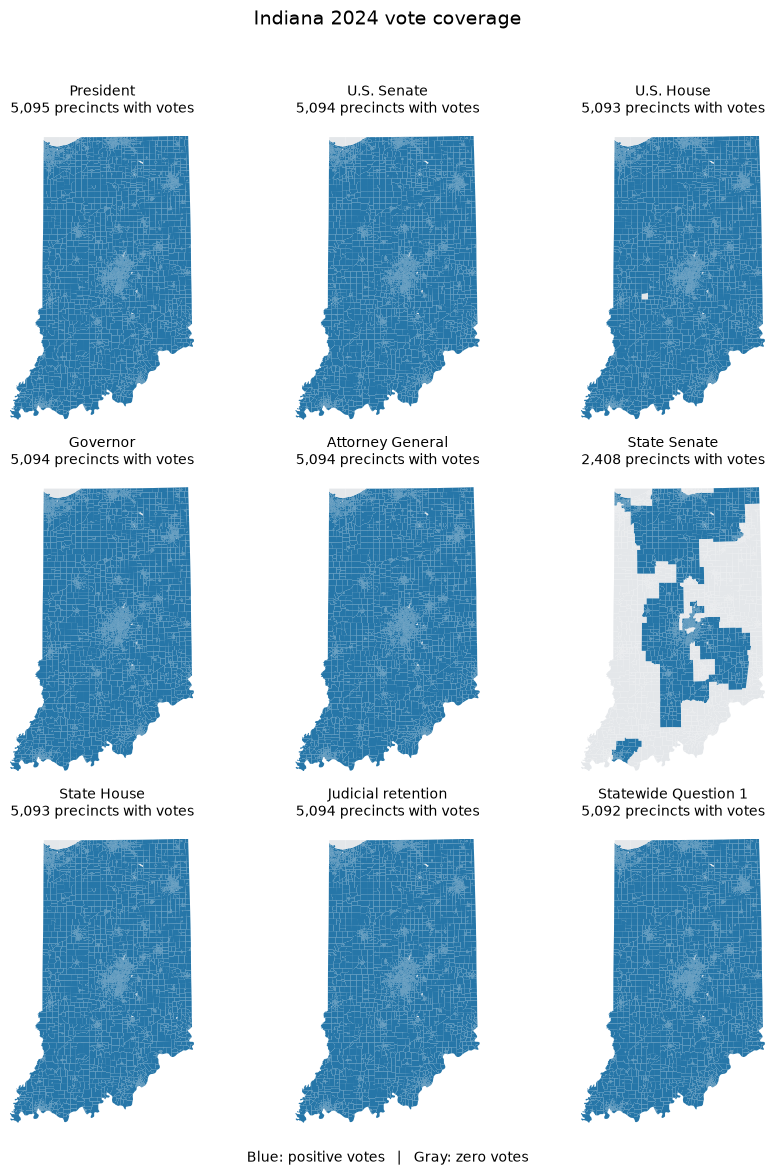

In [10]:
if PLOT_COVERAGE:
    plot_vote_coverage(allocated_precincts, vote_fields, detailed=PLOT_DETAILED_COVERAGE)
